# Dự đoán cân nặng theo chiều cao

Dữ liệu gồm 15 người; 13 người làm **tập huấn luyện**, 2 người cao **155 cm** và **160 cm** làm **tập kiểm tra**.

Mô hình: $\text{(cân nặng)} = w_1 \cdot \text{(chiều cao)} + w_0$

## Khai báo và hiển thị dữ liệu

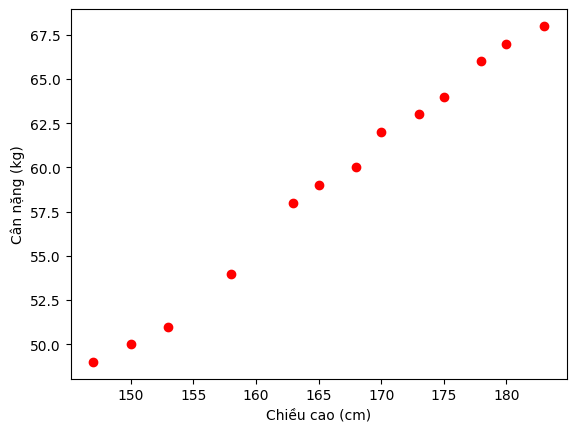

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Chiều cao (cm) – mỗi hàng là một mẫu dữ liệu
X = np.array([[147, 150, 153, 158, 163, 165, 168, 170,
               173, 175, 178, 180, 183]]).T

# Cân nặng tương ứng (kg) – biến mục tiêu
y = np.array([49, 50, 51, 54, 58, 59, 60, 62, 63, 64, 66, 67, 68])

plt.plot(X, y, 'ro')
plt.xlabel('Chiều cao (cm)')
plt.ylabel('Cân nặng (kg)')
plt.show()

Các điểm dữ liệu nằm **gần như trên một đường thẳng**, vì vậy hồi quy tuyến tính có khả năng cho kết quả tốt.

w_0 = -33.735410206298866
w_1 = 0.5592049619425978


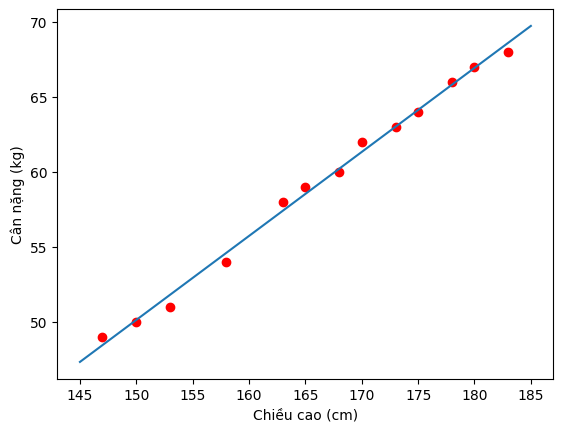

Chiều cao 155 cm, cân nặng thực tế 52 kg, dự đoán 52.94 kg
Chiều cao 160 cm, cân nặng thực tế 56 kg, dự đoán 55.74 kg


In [2]:
# Bước 1: Tạo ma trận Xbar (thêm cột 1 vào trước ma trận X)
# X.shape[0] = 13 là số mẫu -> ones là vector cột gồm 13 số 1, kích thước 13 x 1
ones = np.ones((X.shape[0], 1))
# Ghép theo chiều ngang (axis=1): cột 1 là số 1, cột 2 là chiều cao
# Xbar kích thước 13 x 2, mỗi hàng là [1, x_i] => [1, x_i] . [w_0, w_1] = w_0 + w_1 * x_i
Xbar = np.concatenate((ones, X), axis=1)

# Tính w = (Xbar^T Xbar)^+ Xbar^T y
# Bước 2: A = Xbar^T Xbar, kích thước (2 x 13)(13 x 2) = 2 x 2
#         A = [[N, tổng x_i], [tổng x_i, tổng x_i^2]] = [[13, 2163], [2163, 361527]]
A = np.dot(Xbar.T, Xbar)
# Bước 3: b = Xbar^T y, kích thước (2 x 13)(13) = 2
#         b = [tổng y_i, tổng x_i*y_i] = [771, 129198]
b = np.dot(Xbar.T, y)
# Bước 4: Giải hệ phương trình chuẩn A w = b bằng giả nghịch đảo: w = A^+ b
#         pinv vẫn cho nghiệm khi A không khả nghịch (inv sẽ báo lỗi)
w = np.dot(np.linalg.pinv(A), b)

# w là mảng 1 chiều: w[0] là hệ số chệch w_0, w[1] là hệ số góc w_1
w_0, w_1 = w[0], w[1]
print('w_0 =', w_0)
print('w_1 =', w_1)

# Vẽ đường hồi quy qua hai điểm đầu mút
x_line = np.linspace(145, 185, 2)
y_line = w_0 + w_1 * x_line
plt.plot(X, y, 'ro')
plt.plot(x_line, y_line)
plt.xlabel('Chiều cao (cm)')
plt.ylabel('Cân nặng (kg)')
plt.show()

# Dự đoán trên tập kiểm tra
pred_155 = w_1 * 155 + w_0   # cân nặng dự đoán của người cao 155 cm
pred_160 = w_1 * 160 + w_0   # cân nặng dự đoán của người cao 160 cm
print('Chiều cao 155 cm, cân nặng thực tế 52 kg, dự đoán %.2f kg' % pred_155)
print('Chiều cao 160 cm, cân nặng thực tế 56 kg, dự đoán %.2f kg' % pred_160)

In [3]:
from sklearn import linear_model

model = linear_model.LinearRegression()
model.fit(X, y)   # mỗi mẫu dữ liệu là một hàng

print("Kết quả từ scikit-learn:")
print("w1 =", model.coef_[0])     # hệ số góc
print("w0 =", model.intercept_)   # hệ số chệch

print("Kết quả tính toán thủ công:")
print("w1 =", w[1])
print("w0 =", w[0])

Kết quả từ scikit-learn:
w1 = 0.5592049619396674
w0 = -33.73541020580774
Kết quả tính toán thủ công:
w1 = 0.5592049619425978
w0 = -33.735410206298866
